In [1]:
import pandas as pd 
import matplotlib.pyplot as plt
import numpy as np 
import scipy.stats as stats
import seaborn as sns 
import warnings
from sklearn.linear_model import LinearRegression 


from sklearn.model_selection import train_test_split 
from sklearn.metrics import confusion_matrix 
from sklearn.metrics import accuracy_score 
from sklearn.metrics import classification_report 
from sklearn import metrics
from sklearn import svm
from sklearn.model_selection import cross_val_score
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv("temperature-medie-annuali-1950-2024.csv")

In [3]:
df

,country,year,iso_code,mean_temperature
0,Afghanistan,1950,AFG,11.41
1,Afghanistan,1951,AFG,12.25
2,Afghanistan,1952,AFG,12.39
3,Afghanistan,1953,AFG,12.74
4,Afghanistan,1954,AFG,12.05
...,...,...,...,...
14695,Zimbabwe,2020,ZWE,21.94
14696,Zimbabwe,2021,ZWE,21.89
14697,Zimbabwe,2022,ZWE,21.83
14698,Zimbabwe,2023,ZWE,22.09


In [4]:
#df.dtypes()

In [5]:
df.isnull().sum()

country             0
year                0
iso_code            0
mean_temperature    0
dtype: int64

In [6]:
df['mean_temperature'] = df['mean_temperature'] * 9/5 + 32

df.head()

,country,year,iso_code,mean_temperature
0,Afghanistan,1950,AFG,52.538
1,Afghanistan,1951,AFG,54.050
2,Afghanistan,1952,AFG,54.302
3,Afghanistan,1953,AFG,54.932
4,Afghanistan,1954,AFG,53.690


<Axes: title={'center': 'Average Temperature by Year'}, xlabel='Year', ylabel='Temperature (°C)'>

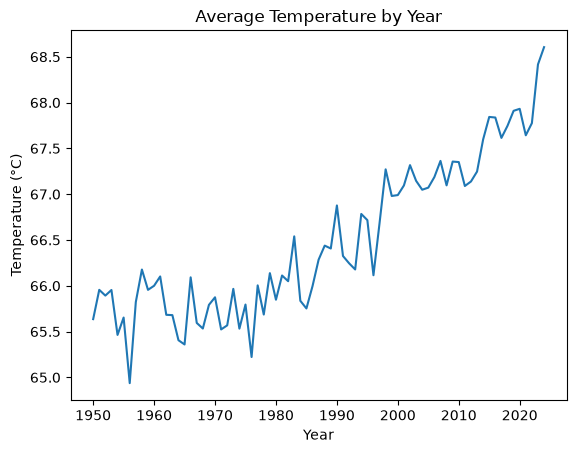

In [7]:
yearly_avg_temp = df.groupby('year')['mean_temperature'].mean()

yearly_avg_temp.plot(
    kind='line',
    title='Average Temperature by Year',
    ylabel='Temperature (°C)',
    xlabel='Year',
    legend=False
)



<Axes: title={'center': 'Average Temperature by Country'}, xlabel='Country', ylabel='Temperature (°C)'>

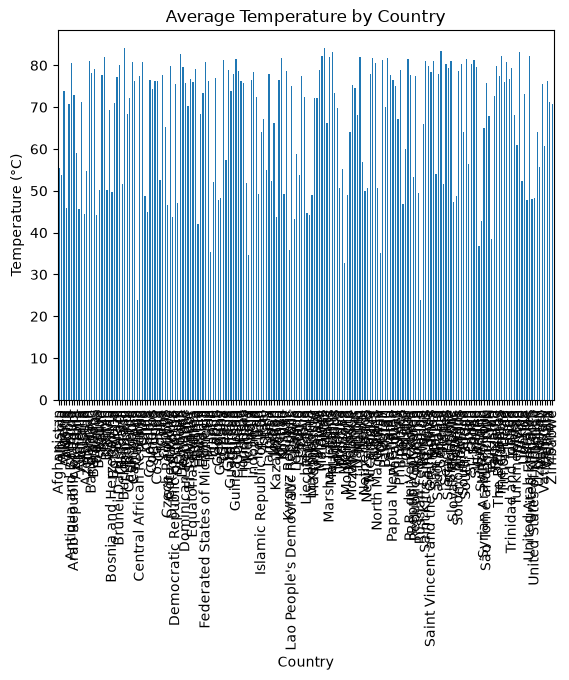

In [8]:
avg_temp_by_country = df.groupby('country', as_index=False)['mean_temperature'].mean()

avg_temp_by_country.plot(
    x='country',
    y='mean_temperature',
    kind='bar',
    title='Average Temperature by Country',
    ylabel='Temperature (°C)',
    xlabel='Country',
    legend=False
)

In [9]:
df.shape[0]


14700

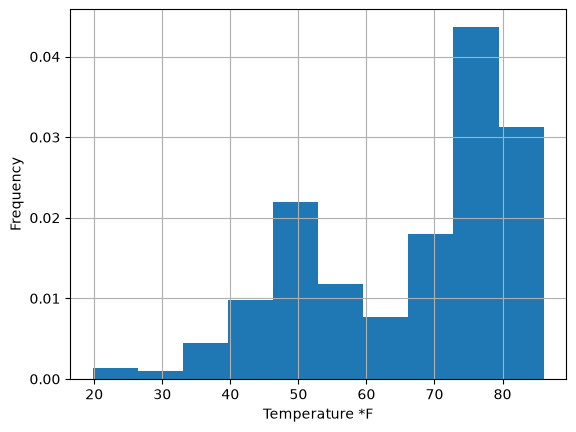

In [10]:
df['mean_temperature'].hist(density = True, bins = 10)
plt.xlabel('Temperature *F')
plt.ylabel('Frequency')
plt.show()

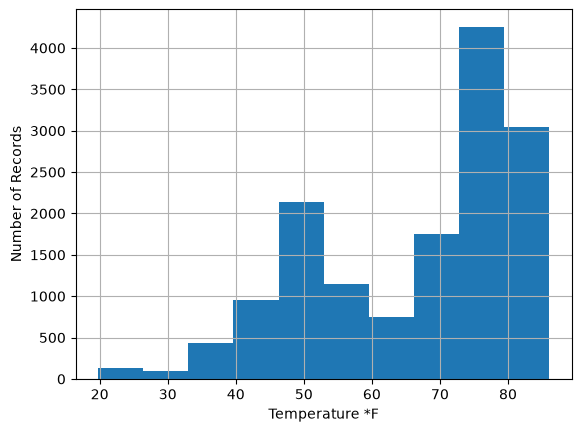

In [11]:
df['mean_temperature'].hist(density = False, bins = 10)
plt.xlabel('Temperature *F')
plt.ylabel('Number of Records')
plt.show()

In [12]:
df2 = pd.read_csv("emissioni-co2-globali-per-paese-1950-2024.csv")

In [13]:
df2.shape

(14925, 10)

In [14]:
df2[df2.isna().any(axis=1)]

,country,year,iso_code,co2,co2_per_capita,coal_co2,oil_co2,gas_co2,cement_co2,consumption_co2
0,Afghanistan,1950,AFG,0.084272,0.010837,0.021068,0.063204,0.0,0.000000,NaN
1,Afghanistan,1951,AFG,0.091600,0.011625,0.025648,0.065952,0.0,0.000000,NaN
2,Afghanistan,1952,AFG,0.091600,0.011468,0.031708,0.059892,0.0,0.000000,NaN
3,Afghanistan,1953,AFG,0.106256,0.013123,0.037949,0.068307,0.0,0.000000,NaN
4,Afghanistan,1954,AFG,0.106256,0.012945,0.042502,0.063754,0.0,0.000000,NaN
...,...,...,...,...,...,...,...,...,...,...
14920,Zimbabwe,2020,ZWE,8.490839,0.546847,4.931744,3.063104,NaN,0.495991,10.481925
14921,Zimbabwe,2021,ZWE,10.222778,0.647125,5.935680,3.744608,NaN,0.542490,12.359282
14922,Zimbabwe,2022,ZWE,12.231845,0.761205,7.165461,4.678891,NaN,0.387493,13.611954
14923,Zimbabwe,2023,ZWE,13.443295,0.822681,8.284867,4.770935,NaN,0.387493,15.319530


In [15]:
df.columns[df.isna().any()].tolist()

[]

In [16]:
'''print(df2.isnull().sum())

print(df2.isnull().sum())

df2 = df2.dropna()'''

'print(df2.isnull().sum())\n\nprint(df2.isnull().sum())\n\ndf2 = df2.dropna()'

In [17]:
df2[df2['consumption_co2'].isnull()]

,country,year,iso_code,co2,co2_per_capita,coal_co2,oil_co2,gas_co2,cement_co2,consumption_co2
0,Afghanistan,1950,AFG,0.084272,0.010837,0.021068,0.063204,0.0,0.000000,NaN
1,Afghanistan,1951,AFG,0.091600,0.011625,0.025648,0.065952,0.0,0.000000,NaN
2,Afghanistan,1952,AFG,0.091600,0.011468,0.031708,0.059892,0.0,0.000000,NaN
3,Afghanistan,1953,AFG,0.106256,0.013123,0.037949,0.068307,0.0,0.000000,NaN
4,Afghanistan,1954,AFG,0.106256,0.012945,0.042502,0.063754,0.0,0.000000,NaN
...,...,...,...,...,...,...,...,...,...,...
14886,Zimbabwe,1986,ZWE,13.068023,1.454819,10.849104,1.894288,NaN,0.324631,NaN
14887,Zimbabwe,1987,ZWE,15.170106,1.633891,13.003001,1.821446,NaN,0.345659,NaN
14888,Zimbabwe,1988,ZWE,16.029461,1.672680,13.402912,2.300992,NaN,0.325557,NaN
14889,Zimbabwe,1989,ZWE,16.113653,1.633450,13.611760,2.202064,NaN,0.299830,NaN


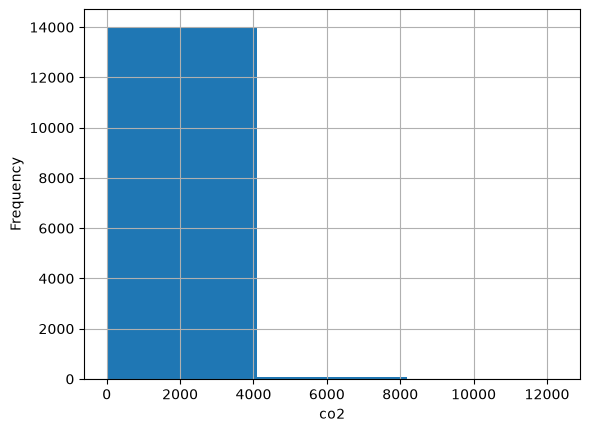

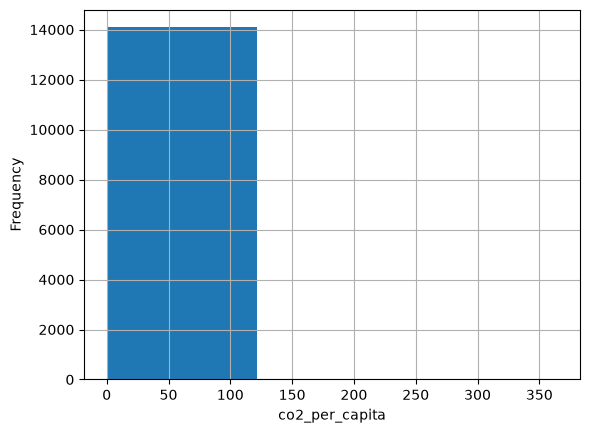

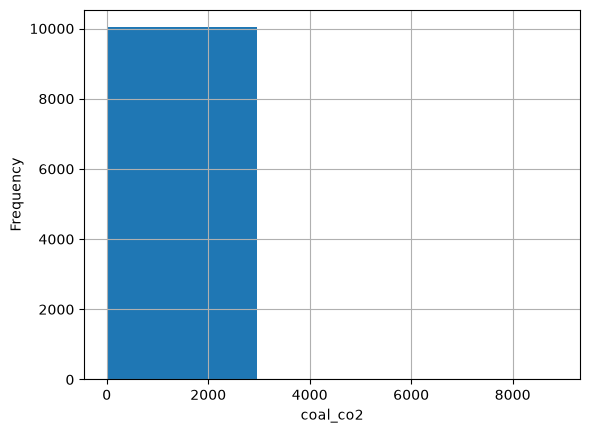

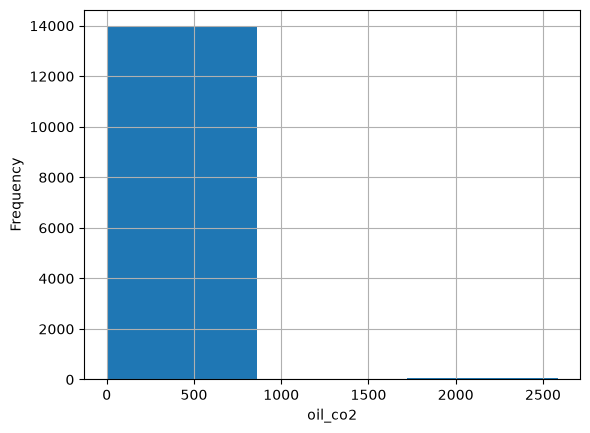

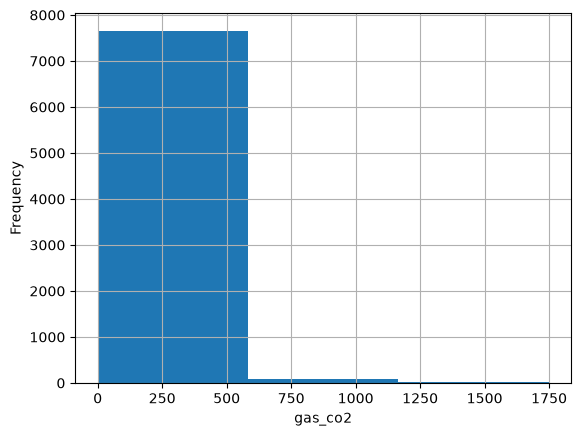

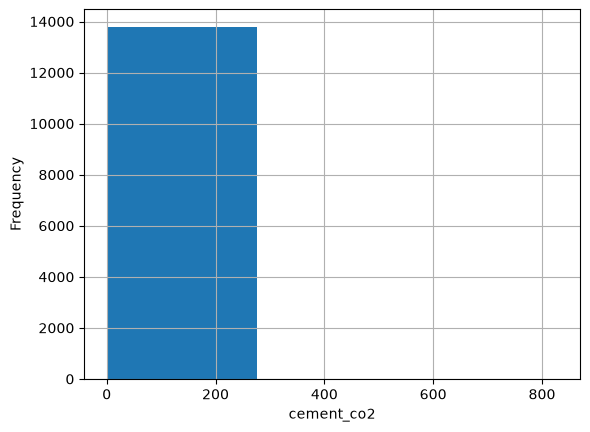

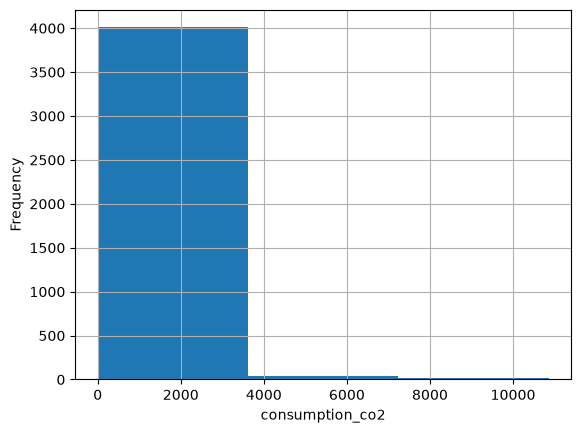

In [18]:
for attr in ['co2', 'co2_per_capita', 'coal_co2', 'oil_co2', 'gas_co2', 'cement_co2', 'consumption_co2']:
    df2[attr].hist(density = False, bins = 3 )
    plt.xlabel(attr)
    plt.ylabel('Frequency')
    plt.show()

In [20]:
for attr in ['co2', 'co2_per_capita', 'coal_co2', 'oil_co2', 'gas_co2', 'cement_co2', 'consumption_co2']:
    print(df2[attr].describe())
    print(attr ,round(df2[attr].mean(),2))

count    14086.000000
mean       111.903296
std        550.619005
min          0.000000
25%          0.765945
50%          6.390941
75%         43.733862
max      12289.037109
Name: co2, dtype: float64
co2 111.9
count    14086.000000
mean         4.210654
std          7.445173
min          0.000000
25%          0.362036
50%          1.649128
75%          5.722017
max        364.790833
Name: co2_per_capita, dtype: float64
co2_per_capita 4.21
count    10052.000000
mean        65.221744
std        375.399260
min          0.000000
25%          0.053592
50%          1.588705
75%         14.730824
max       8886.020508
Name: coal_co2, dtype: float64
coal_co2 65.22
count    14026.000000
mean        40.284451
std        171.983789
min          0.000000
25%          0.586240
50%          3.312256
75%         19.685696
max       2584.129883
Name: oil_co2, dtype: float64
oil_co2 40.28
count    7765.000000
mean       35.036618
std       127.541175
min         0.000000
25%         0.172004
50%     

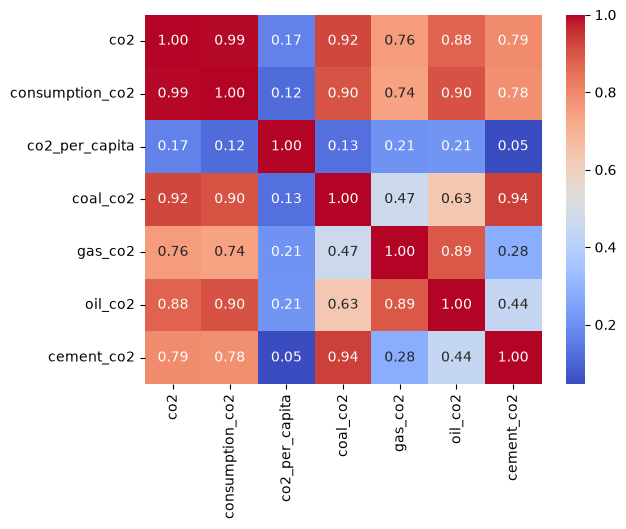

In [32]:
corr = df2[['co2', 'consumption_co2', 'co2_per_capita', 'coal_co2', 'gas_co2', 'oil_co2', 'cement_co2']].corr(method='pearson')

sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm')
plt.show()

In [33]:
temp_co2_data = pd.merge(df, df2, on=['country', 'year'], how='inner')

In [34]:
temp_co2_data.shape

(12900, 12)

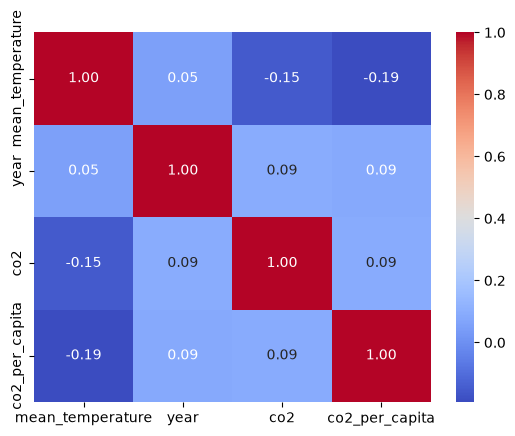

In [35]:
corr2 = temp_co2_data[['mean_temperature', 'year','co2','co2_per_capita']].corr(method='pearson')
sns.heatmap(corr2, annot=True, fmt=".2f", cmap='coolwarm')
plt.show()

In [36]:
X = temp_co2_data[['year', 'co2', 'consumption_co2', 'co2_per_capita', 'coal_co2', 'gas_co2', 'oil_co2', 'cement_co2']]
y = temp_co2_data['mean_temperature']

In [37]:
model_data = temp_co2_data[X.columns.tolist() + [y.name]].copy()

missingness_by_column = (
    model_data.isna() # Calculate missing values for each column
    .agg(["sum", "mean"])
    .T
    .rename(columns={"sum": "missing_rows", "mean": "missing_fraction"})
    .sort_values("missing_fraction", ascending=False)
) #

print("Missingness by model column:") 
print(missingness_by_column.to_string()) #

missingness_by_country = (
    temp_co2_data.assign(
        rows_with_missing_features=X.isna().any(axis=1),
        missing_temperature=y.isna(),
    )
    .groupby("country")
    .agg(
        rows=("year", "size"),
        rows_with_missing_features=("rows_with_missing_features", "sum"),
        missing_temperature=("missing_temperature", "sum"),
    )
) #check for missing values by country

missingness_by_country["feature_missing_fraction"] = (
    missingness_by_country["rows_with_missing_features"] / missingness_by_country["rows"]
)

print("\nCountries with the most rows missing at least one feature:")
print(missingness_by_country.sort_values("feature_missing_fraction", ascending=False).head(15).to_string())

Missingness by model column:
                  missing_rows  missing_fraction
consumption_co2         9346.0          0.724496
gas_co2                 6134.0          0.475504
coal_co2                4154.0          0.322016
cement_co2               898.0          0.069612
oil_co2                  680.0          0.052713
co2_per_capita           628.0          0.048682
co2                      628.0          0.048682
year                       0.0          0.000000
mean_temperature           0.0          0.000000

Countries with the most rows missing at least one feature:
                     rows  rows_with_missing_features  missing_temperature  feature_missing_fraction
country                                                                                             
Afghanistan            75                          75                    0                       1.0
Algeria                75                          75                    0                       1.0
Andorra          

In [38]:
candidate_features = ['year', 'co2', 'co2_per_capita'] # Define model features

candidate_data = temp_co2_data[candidate_features + ['mean_temperature']] # Select model features and the target variable

print("Candidate feature missingness:")
print(candidate_data.isna().mean().sort_values(ascending=False).to_string()) # check for missing values in candidate features by percentage

candidate_country_coverage = (
    temp_co2_data.assign(
        rows_missing_candidate=(temp_co2_data[candidate_features].isna().any(axis=1))
    )
    .groupby('country')
    .agg(
        rows=('year', 'size'),
        rows_missing_candidate=('rows_missing_candidate', 'sum'),
    ) 
) #

candidate_country_coverage['missing_fraction'] = (
    candidate_country_coverage['rows_missing_candidate'] / candidate_country_coverage['rows']
) 


print(candidate_country_coverage.sort_values('missing_fraction', ascending=False).head(15).to_string())

Candidate feature missingness:
co2                 0.048682
co2_per_capita      0.048682
year                0.000000
mean_temperature    0.000000
                  rows  rows_missing_candidate  missing_fraction
country                                                         
San Marino          75                      75          1.000000
Monaco              75                      75          1.000000
Eritrea             75                      44          0.586667
Kosovo              75                      44          0.586667
Marshall Islands    75                      42          0.560000
Namibia             75                      41          0.546667
Tuvalu              75                      40          0.533333
Lesotho             75                      40          0.533333
Andorra             75                      40          0.533333
Botswana            75                      22          0.293333
Maldives            75                      21          0.280000
Bhutan  

In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline


global_temperature_by_year = (
    df.groupby('year', as_index=False)
    .agg(mean_temperature=('mean_temperature', 'mean'))
) 

global_co2_by_year = (
    df2.groupby('year', as_index=False)
    .agg(
        co2=('co2', lambda values: values.sum(min_count=1)),
        co2_per_capita=('co2_per_capita', 'mean'),
    )
) 

global_yearly_data = (
    global_temperature_by_year
    .merge(global_co2_by_year, on='year', how='inner')
    .sort_values('year')
    .reset_index(drop=True)
) 

model_features = ['year', 'co2', 'co2_per_capita']
model_target = 'mean_temperature'
model_data = global_yearly_data[model_features + [model_target]].dropna(subset=[model_target]).copy()

available_years = np.sort(model_data['year'].unique()) 
test_year_count = max(1, int(np.ceil(len(available_years) * 0.2))) 
test_years = available_years[-test_year_count:] 
train_data = model_data[~model_data['year'].isin(test_years)] 
test_data = model_data[model_data['year'].isin(test_years)]

complete_train = train_data.dropna(subset=model_features) 
complete_test = test_data.dropna(subset=model_features) 

if complete_train.empty or complete_test.empty: 
    raise ValueError('Not enough complete annual emissions rows for a time-based model fit.')



feature_variables = ['year', 'co2', 'co2_per_capita']

comparison_models = {} 
results = []

estimator = make_pipeline(
        SimpleImputer(strategy='median', add_indicator=True),
        LinearRegression(),
    ) #
estimator.fit(train_data[feature_variables], train_data[model_target]) #train model 
test_predictions = estimator.predict(test_data[feature_variables]) #get predictions for test data

imputed_model = estimator
print(f"Training years: {train_data['year'].min():.0f}-{train_data['year'].max():.0f}") 
print(f"Held-out years: {test_data['year'].min():.0f}-{test_data['year'].max():.0f}") 
print(f"Training years evaluated: {len(train_data):,}") 
print(f"Shared held-out years used for comparison: {len(test_data):,}") 


Training years: 1950-2009
Held-out years: 2010-2024
Training years evaluated: 60
Shared held-out years used for comparison: 15


In [40]:
lr = LinearRegression(fit_intercept = True)

lr.fit(complete_train[model_features], complete_train[model_target])


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[ 0.03, 0. ,-0.32]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['year','co2','co2_per_capita']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,13.1
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)


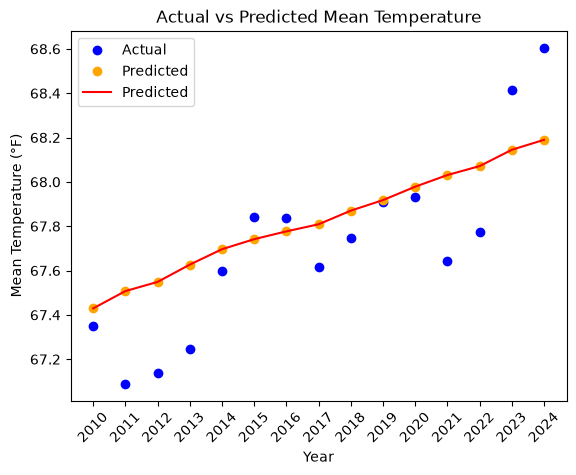

In [42]:
y_pred = lr.predict(complete_test[model_features])

plt.plot(complete_test['year'], complete_test[model_target],'o',label='Actual', color='blue')
plt.plot(complete_test['year'], y_pred, 'o',label='Predicted', color='orange')
plt.plot(complete_test['year'], y_pred, label='Predicted', color='red')
plt.xticks(complete_test['year'], rotation=45)
plt.title('Actual vs Predicted Mean Temperature')

plt.xlabel('Year')
plt.ylabel('Mean Temperature (°F)')
plt.legend()

<p>This model used the CO2 and CO2 per capita columns as features to predict global temperatures. The line graph compares actual average temperatures with predicted temperatures over the years. This shows that the predictions are slightly off from the actual recorded temperatures, with some years spiking significantly and others dropping. However, the trend line mostly aligns with the recorded data. The Global Temperature Prediction Model achieved an R^2 of 0.578 with linear regression, indicating that while we have part of the picture, we need more information on how current trends form to better understand where we should be versus where we are. However, in 2023 and 2024, actual temperatures were notably higher than the model's predictions, indicating there is a significant rise.</p>


In [ ]:
from sklearn.metrics import r2_score
import numpy as np

predictions = lr.predict(complete_test[model_features])
actual = complete_test[model_target]

print(f"R²:   {r2_score(actual, predictions):.3f}")

R²:   0.579


<p>The Global Temperature Prediction Model generally captures the trend in the recorded data toward rising temperatures; however, with an r^2 value of 0.579, it still misses part of the bigger picture. This is likely because it omits greenhouse gas emissions data, which also affects climate change. While this predictor model is missing some of the data needed to be more accurate, it still indicates that, in terms of our track in global temperatures, we are higher than we should be due to some of the spikes in the actual temperatures of 2023 and 2024 compared to what was able to be predicted. This suggests we should further reduce carbon emissions to combat rising temperatures before it is too late.</p>